## Explainability (RQ3)

Which questions drive the predictions, and do SHAP, LIME and the EBM's own importances agree? All three explain the same model: an EBM with `interactions=0`, so it is purely additive (one score per input, added up).

To make the comparison fair, the three methods are measured on the **same test rows** and on the **same scale** (log-odds). This is repeated over 10 train/test splits, so the result does not depend on one lucky split.

Since the label is the sum of the answers, every question has equal weight under the true rule. Differences in importance reflect how answers are spread in this sample, not clinical importance.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline
from interpret.glassbox import ExplainableBoostingClassifier
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import RepeatedStratifiedKFold

PROCESSED = Path("../data/processed")
TABLES = Path("../results/tables")
FIGURES = Path("../results/figures")

SEED = 42
GROUPS = ["toddler", "child", "adolescent", "adult"]
QUESTIONS = [f"A{i}" for i in range(1, 11)]
FEATURES = QUESTIONS + ["age", "male", "jaundice", "family_asd"]
# positions of the 0/1 columns (all except age)
CATEGORICAL = [i for i, f in enumerate(FEATURES) if f != "age"]

COLUMN, PAGE = 3.5, 7.16  # width of one column and of a full page in the IEEE format (inches)
sns.set_theme(style="whitegrid", font="serif", rc={
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "figure.titlesize": 9, "savefig.dpi": 300, "savefig.bbox": "tight",
})
PAIRS = [("EBM", "SHAP"), ("EBM", "LIME"), ("SHAP", "LIME")]
FEATURE_NAMES = {"age": "Age", "male": "Male", "jaundice": "Jaundice", "family_asd": "Family ASD"}

### 1. Three ways of measuring importance

* **EBM**: the model's own score for each input. No extra method is needed.
* **SHAP**: shares out the prediction between the inputs, compared with a set of reference rows (the background).
* **LIME**: changes one row a little, many times, and fits a simple straight-line model to what happens.

For each method the importance of an input is the average size of its effect over the test rows.

In [2]:
# log-odds = the model's score before it is turned into a probability.
# 0 means 50%, above 0 means more than 50%, below 0 means less than 50%.
# All three methods explain this same number
def log_odds(ebm):
    return lambda d: ebm.decision_function(pd.DataFrame(d, columns=FEATURES))


# EBM = Explainable Boosting Machine.
# eval_terms gives the EBM's own score for each input, for every row
def ebm_scores(ebm, X_test):
    return ebm.eval_terms(X_test)


# SHAP = SHapley Additive exPlanations. It gives each input a share of the prediction.
# Example: the score is 3.0, the average score is 1.0, and A1 gets +0.5 of the difference.
# background = the rows that give the "average" to compare with
def shap_values(ebm, background, X_test):
    explainer = shap.Explainer(log_odds(ebm), background, seed=SEED)
    return explainer(X_test)


# LIME = Local Interpretable Model-agnostic Explanations.
# It changes one row a little, many times, and sees which inputs move the prediction most.
# mode="regression" because the log-odds is a number, not a class
def lime_weights(ebm, X_train, X_test):
    explainer = LimeTabularExplainer(X_train.to_numpy(float), mode="regression", feature_names=FEATURES,
                                     categorical_features=CATEGORICAL, random_state=SEED)
    predict = log_odds(ebm)
    weights = np.zeros((len(X_test), len(FEATURES)))
    for n, row in enumerate(X_test.to_numpy(float)):
        # by default LIME returns 10 inputs. We ask for all 14
        exp = explainer.explain_instance(row, predict, num_features=len(FEATURES))
        for i, w in exp.as_map()[1]:
            weights[n, i] = w
    return weights

In [3]:
# 5 folds, done 2 times = 10 train/test splits
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

importance = {g: [] for g in GROUPS}  # one table for each split
check = []
first_shap = {}

for g in GROUPS:
    df = pd.read_csv(PROCESSED / f"{g}.csv")
    X, y = df[FEATURES], df["asd"]
    for split, (train, test) in enumerate(cv.split(X, y)):
        X_train, X_test = X.iloc[train], X.iloc[test]

        # SMOTE makes new rows for the smaller class, e.g. 40 "yes" rows become 100 (see notebook 05).
        # interactions=0: the EBM looks at each input alone, no pairs
        model = Pipeline([
            ("smote", SMOTENC(categorical_features=CATEGORICAL, random_state=SEED)),
            ("clf", ExplainableBoostingClassifier(interactions=0, random_state=SEED)),
        ]).fit(X_train, y.iloc[train])
        ebm = model.named_steps["clf"]

        # 100 training rows as the background for SHAP (all rows if there are fewer)
        background = X_train.sample(min(100, len(X_train)), random_state=SEED)

        # the same test rows for all three methods
        scores = ebm_scores(ebm, X_test)
        sv = shap_values(ebm, background, X_test)
        lime = lime_weights(ebm, X_train, X_test)

        importance[g].append(pd.DataFrame({
            "EBM": np.abs(scores).mean(axis=0),
            "SHAP": np.abs(sv.values).mean(axis=0),
            "LIME": np.abs(lime).mean(axis=0),
        }, index=FEATURES))

        # check: move the EBM scores to the same starting point as SHAP (the background average).
        # After that the two should be the same numbers
        moved = scores - ebm.eval_terms(background).mean(axis=0)
        check.append({"group": g, "split": split, "largest difference": np.abs(sv.values - moved).max()})

        if split == 0:
            first_shap[g] = sv  # kept for the plot at the end
    print(g, "done")

toddler done


child done


adolescent done


adult done


### 2. Is SHAP independent of the EBM?

No. For an additive model, SHAP must give back the model's own scores. The only difference is the starting point: the EBM measures from the average of its training data, SHAP from the average of the background rows. The table shows the largest difference between the two, after moving both to the same starting point.

In [4]:
pd.DataFrame(check).groupby("group", sort=False)["largest difference"].max().to_frame()

,largest difference
group,
toddler,1.278977e-13
child,6.039613e-14
adolescent,2.309264e-14
adult,1.136868e-13


The differences are zero (only rounding error). So **EBM and SHAP are two views of the same numbers**, and their agreement below is a consistency check, not separate evidence. LIME is the only method here that works in a different way.

### 3. Importance per method and age group

Each column is scaled to sum to 1 so the three methods can be shown side by side. The values are the average over the 10 splits.

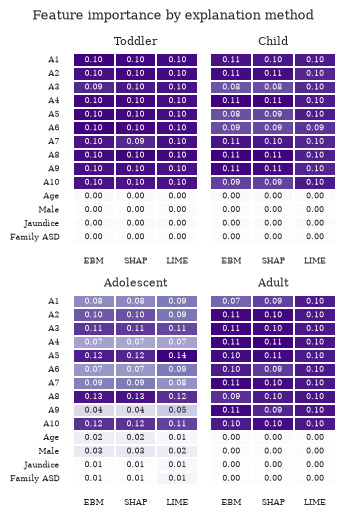

In [5]:
# make each method add up to 1 in every split, then take the average over the splits
scaled = pd.concat({g: sum(imp / imp.sum() for imp in importance[g]) / len(importance[g]) for g in GROUPS}, axis=1)
scaled.to_csv(TABLES / "feature_importance.csv")

fig, axes = plt.subplots(2, 2, figsize=(COLUMN, 5.2), sharey=True)
for ax, g in zip(axes.flat, GROUPS):
    sns.heatmap(scaled[g].rename(index=FEATURE_NAMES), annot=True, fmt=".2f", annot_kws={"size": 5.5},
                cmap="Purples", cbar=False, linewidths=0.3, ax=ax)
    ax.set_title(g.capitalize())
    ax.tick_params(axis="y", rotation=0, labelsize=6)
    ax.tick_params(axis="x", labelsize=6)
fig.suptitle("Feature importance by explanation method")
fig.tight_layout()
fig.savefig(FIGURES / "fig_importance_by_method.png")

### 4. Do the methods agree?

Two measures per pair of methods, computed in every split:

* **Spearman's ρ** between the rankings of the ten questions (1 = same order, 0 = no relation)
* **Top-5 overlap**: how many of the five most important questions are shared (out of 5)

Only A1–A10 are ranked. The four personal details are near zero under every method, so including them would make the agreement look better than it is.

**What would chance give?** Two random rankings of ten questions share 2.5 of their top five on average, and their Spearman's ρ is 0 on average. The overlap has to be clearly above 2.5 to mean anything.

In [6]:
rows = []
for g in GROUPS:
    for split, imp in enumerate(importance[g]):
        # use only the ten questions here
        imp = imp.loc[QUESTIONS]
        for a, b in PAIRS:
            # the five most important questions for each method
            top_a, top_b = set(imp[a].nlargest(5).index), set(imp[b].nlargest(5).index)
            # Spearman compares the order of the questions, not the exact values
            rows.append({"group": g, "split": split, "pair": f"{a} vs {b}",
                         "spearman": imp[a].corr(imp[b], method="spearman"),
                         "top-5 overlap": len(top_a & top_b)})
per_split = pd.DataFrame(rows)

# average and spread over the 10 splits
agreement = per_split.groupby(["group", "pair"], sort=False)[["spearman", "top-5 overlap"]].agg(["mean", "std"])
agreement.columns = ["spearman", "spearman std", "top-5 overlap", "top-5 overlap std"]
agreement.reset_index().to_csv(TABLES / "explanation_agreement.csv", index=False)
agreement.round(2)

spearman  spearman std  top-5 overlap  \
group      pair                                                  
toddler    EBM vs SHAP       0.65          0.23            3.9   
           EBM vs LIME       0.60          0.22            3.2   
           SHAP vs LIME      0.62          0.18            3.6   
child      EBM vs SHAP       0.96          0.03            4.8   
           EBM vs LIME       0.22          0.16            2.8   
           SHAP vs LIME      0.28          0.17            2.8   
adolescent EBM vs SHAP       0.98          0.03            4.9   
           EBM vs LIME       0.90          0.10            4.2   
           SHAP vs LIME      0.88          0.11            4.2   
adult      EBM vs SHAP       0.67          0.18            3.7   
           EBM vs LIME       0.27          0.25            2.9   
           SHAP vs LIME      0.23          0.11            2.6   

                         top-5 overlap std  
group      pair                             
toddler    EBM vs SHAP                0.32  
           EBM vs LIME                1.03  
           SHAP vs LIME               0.84  
child      EBM vs SHAP                0.42  
           EBM vs LIME                0.79  
           SHAP vs LIME               0.79  
adolescent EBM vs SHAP                0.32  
           EBM vs LIME                0.63  
           SHAP vs LIME               0.63  
adult      EBM vs SHAP                0.67  
           EBM vs LIME                0.74  
           SHAP vs LIME               0.52

In [7]:
# chance level: the top-5 overlap of two random orders of ten questions
rng = np.random.default_rng(SEED)
random_overlap = [len(set(rng.permutation(10)[:5]) & set(rng.permutation(10)[:5])) for _ in range(20000)]
print(f"top-5 overlap by chance: {np.mean(random_overlap):.2f}")

top-5 overlap by chance: 2.51


### 5. Top questions per age group

Ranked by the average importance over the 10 splits.

In [8]:
top = pd.DataFrame({
    (g, m): scaled[g][m].loc[QUESTIONS].nlargest(5).index.tolist()
    for g in GROUPS for m in ["EBM", "SHAP", "LIME"]
}, index=[f"#{i}" for i in range(1, 6)])
top

toddler           child           adolescent           adult          
       EBM SHAP LIME   EBM SHAP LIME        EBM SHAP LIME   EBM SHAP LIME
#1      A6   A8   A8    A8   A4   A1         A8   A8   A5    A3   A4   A4
#2      A1   A4   A2    A4   A8  A10         A5   A5   A8    A4   A5   A9
#3      A5   A1   A6    A9   A9   A4        A10  A10  A10    A7   A3   A8
#4      A4   A2   A1    A2   A2   A5         A3   A3   A3    A2   A2   A7
#5      A8   A6   A5    A7   A7   A8         A2   A2   A2    A9   A7  A10

Comparing the same item number across groups needs care. Q-CHAT-10 and the three AQ-10 versions ask different questions under the same label (see `app/questions.py`), so "A9 matters for adults and children" may mean two different questions.

### 6. SHAP summary plots

From the first split. Each dot is one person in the test set. Red dots are answers scored 1 (towards autistic traits); points to the right push the prediction towards "ASD traits".

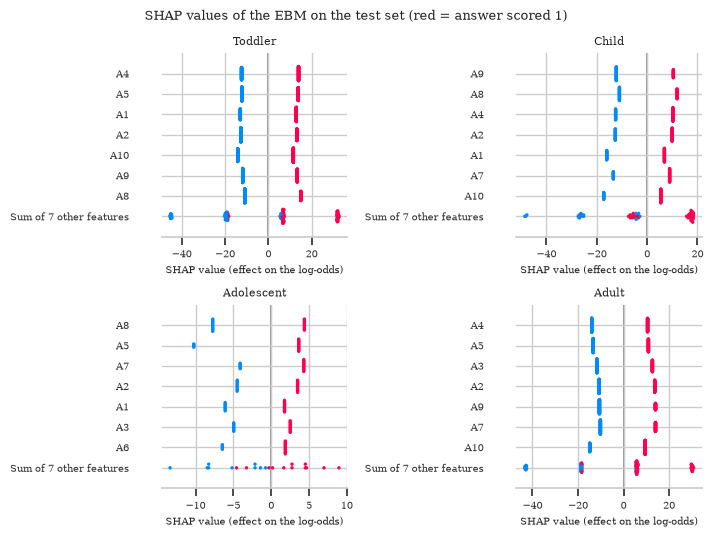

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(PAGE, 5.4))
for ax, g in zip(axes.flat, GROUPS):
    sv = first_shap[g]
    # full names for the plot
    sv.feature_names = [FEATURE_NAMES.get(f, f) for f in FEATURES]
    shap.plots.beeswarm(sv, max_display=8, show=False, ax=ax, plot_size=None, color_bar=False, s=6)
    ax.set_title(g.capitalize())
    ax.set_xlabel("SHAP value (effect on the log-odds)", fontsize=7)
    ax.tick_params(labelsize=7)
fig.suptitle("SHAP values of the EBM on the test set (red = answer scored 1)")
fig.tight_layout()
fig.savefig(FIGURES / "fig_shap_beeswarm.png")

### 7. Answer to RQ3

* **All ten questions matter about equally.** For toddlers, children and adults each question gets about 0.08–0.11 of the total importance under every method, close to the 0.10 that the equal-weight scoring rule implies. The model has learned the rule. Adolescents (101 records) spread more (0.04–0.14), because the model is fitted on very little data.
* **EBM and SHAP are the same numbers.** After moving both to the same starting point, the SHAP values equal the EBM's own scores (largest difference about 10⁻¹³). Their agreement is therefore a consistency check and not separate evidence.
* **Why EBM and SHAP still rank differently in two groups.** The ranking agreement is very high for children and adolescents (ρ = 0.96 and 0.98, top-5 overlap 4.8 and 4.9) but lower for toddlers and adults (ρ = 0.65 and 0.67, overlap 3.9 and 3.7). The only difference between the two is the starting point: the EBM measures from its training data after SMOTE, SHAP from the original background rows. Toddlers (71 % positive) and adults (27 % positive) are the two unbalanced groups, so SMOTE moves the starting point most there. Because the ten importances are almost equal, this small shift is enough to reorder them.
* **LIME agrees much less.** LIME matches the other two for adolescents (ρ about 0.9, overlap 4.2) and partly for toddlers (ρ about 0.6, overlap 3.2–3.6). For children and adults it does not: ρ is only 0.22–0.28 and the top-5 overlap is 2.6–2.9, which is no better than the 2.5 expected by chance. LIME gives every question almost the same weight there (0.098–0.101 for adults), so its ranking is mostly noise.
* **The rankings are not stable.** Across the 10 splits the standard deviation of ρ is up to 0.25. A ranking from a single split, as in the first version of this analysis, should not be trusted.
* **Personal details hardly matter.** Age, sex, jaundice and family history sit at the bottom of every ranking, as expected when the label depends on the ten answers only.
* **Reading these results.** The three methods agree on the main point: all ten answers count about equally and the personal details do not. They do not agree reliably on *which* questions come first, because there is no real order to find. The explanations are useful for showing why one person got their result. They should not be read as a finding about which question matters most for autism.